# SarcasTone: Multimodal Sarcasm Detection Using Text and Speech Prosody
**Pipeline:** MUStARD (690 TV-show utterances, video+audio+text, binary sarcasm label) → frozen encoders (RoBERTa-large, WavLM-large, speech-emotion model) + hand-crafted prosody → text-only vs speech-only vs multimodal (with explicit *text-sentiment vs speech-emotion mismatch* features) → repeated stratified CV + cross-show test → auto-generated **PDF report** (last cell).

## Vast.ai setup (best price/performance for THIS notebook)
The encoders are frozen and run once (~5 min of GPU). Most of the run is **CPU-bound** (pYIN pitch tracking + ~4,000 logistic-regression fits), so a cheap GPU with a decent CPU is the best deal.

| Setting | Recommendation |
|---|---|
| GPU | **1× RTX 3090 (24 GB)** best value; 1× RTX 4090 if a fast host is cheaper. Do **not** rent A100/H100: no speed-up here |
| CPU | **≥ 8 vCPU** (16 is nicer; pitch tracking + LR fits run on CPU) |
| RAM | ≥ 32 GB |
| Disk | **40 GB** (image ≈ 15 GB + models ≈ 5 GB + data ≈ 2 GB + pip cache) |
| Network | ≥ 300 Mbps download, reliability ≥ 98 % |
| Type | On-demand (short run; interruptible risks a restart) |
| Image | Vast "PyTorch" template, Jupyter launch mode |

**Expected runtime:** ≈ 20–30 min on a 3090/4090 with 8–16 vCPU (most of it is downloads + training ~4,000 small classifiers). Budget ~1 h of rental to be safe → roughly $0.20–0.50 total. Re-runs after a crash are much faster (features are cached).
Set your hourly price in cell 2 (`VAST_PRICE_PER_HOUR`) so the report prints the cost.

**Workflow:** rent → open Jupyter → upload this notebook → *Run All* → download `sarcastone_outputs.zip` (contains `SarcasTone_Report.pdf`) → **destroy the instance** (stopped instances still bill for disk).


In [1]:
import sys, os, shutil, subprocess

def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    return r.returncode, (r.stdout + r.stderr)

# 1) system packages (ffmpeg for audio extraction, libsndfile for soundfile)
sudo = "" if (not hasattr(os, "geteuid") or os.geteuid() == 0) else "sudo "
if shutil.which("ffmpeg") is None:
    sh(f"{sudo}apt-get update -qq && {sudo}apt-get install -y -qq ffmpeg libsndfile1 wget unzip")

# 2) python packages, installed into THIS notebook's interpreter
PKGS = ['torch', 'transformers>=4.40', 'librosa>=0.10', 'soundfile', 'scikit-learn', 'pandas', 'matplotlib',
        'seaborn', 'tabulate', 'joblib', 'huggingface_hub', 'scipy', 'tqdm', 'reportlab', 'jinja2',
        'imageio-ffmpeg']
quoted = " ".join(f'"{p}"' for p in PKGS)
rc, out = sh(f"{sys.executable} -m pip install -q {quoted}")
if rc != 0:  # externally-managed Python (PEP 668) -> retry with the override flag
    rc, out = sh(f"{sys.executable} -m pip install -q --break-system-packages {quoted}")
if rc != 0:
    print(out[-2000:]); raise RuntimeError("pip install failed - see log above")

# 3) fallback: if apt could not install ffmpeg, use the static binary shipped with imageio-ffmpeg
if shutil.which("ffmpeg") is None:
    import imageio_ffmpeg
    os.makedirs("/tmp/ffbin", exist_ok=True)
    link = "/tmp/ffbin/ffmpeg"
    if not os.path.exists(link):
        os.symlink(imageio_ffmpeg.get_ffmpeg_exe(), link)
    os.environ["PATH"] = "/tmp/ffbin:" + os.environ["PATH"]
print("ffmpeg:", shutil.which("ffmpeg"))

# 4) sanity check
import torch
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available(), "|",
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

ffmpeg: /tmp/ffbin/ffmpeg


torch 2.15.0 | cuda: False | CPU


In [2]:
import os, sys, json, glob, random, time, subprocess, warnings, zipfile, shutil, platform
from pathlib import Path
import numpy as np, pandas as pd, torch
from tqdm.auto import tqdm
warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"   # also silences joblib workers
T0 = time.time()
os.environ.setdefault("VAST_PRICE_PER_HOUR", "0.25")   # <-- put the $/hr shown on your Vast instance card

ROOT = Path(os.environ.get("SARCASTONE_DIR", "/workspace/sarcastone" if os.access("/workspace", os.W_OK) else "./sarcastone")).resolve()
DATA, AUDIO, CACHE, OUT = ROOT/"data", ROOT/"audio16k", ROOT/"cache", ROOT/"outputs"
for p in (DATA, AUDIO, CACHE, OUT, OUT/"figures"):
    p.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("HF_HOME", str(ROOT/"hf"))          # keep model cache on the big disk
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
NJOBS = max(1, int(os.environ.get("SARCASTONE_JOBS", min(8, os.cpu_count() or 1))))

CFG = dict(
    seed=42,
    text_model="roberta-large",                                   # frozen, mean-pooled last layer
    sentiment_model="cardiffnlp/twitter-roberta-base-sentiment-latest",  # text sentiment (neg/neu/pos)
    speech_model="microsoft/wavlm-large",                         # frozen, mid-layer mean+std pooling
    emotion_model="superb/wav2vec2-base-superb-er",               # speech emotion (neu/hap/ang/sad)
    n_splits=5, n_repeats=3,                                      # repeated stratified K-fold
    net_seeds=3, net_epochs=60, net_lr=1e-3, net_wd=1e-2, net_hidden=128, net_dropout=0.4, net_bs=64,
    lr_Cs=[0.1, 0.5, 2, 10, 50, 300, 1000],                       # inner 3-fold CV picks C on TRAIN folds only
    bootstrap=2000,
)

def seed_all(s=CFG["seed"]):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()
print("ROOT:", ROOT, "| device:", DEVICE, "| cpus:", NJOBS)

ROOT: /Users/raghav/Desktop/TrueTone/sarcastone | device: cpu | cpus: 4


/Users/raghav/Desktop/TrueTone/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# ---- Dataset: MUStARD (Castro et al., ACL 2019) -------------------------------------------
# annotations (text, speaker, show, context, label): GitHub   | videos incl. audio: HuggingFace mirror
from urllib.request import urlretrieve
JSON_URL = "https://raw.githubusercontent.com/soujanyaporia/MUStARD/master/data/sarcasm_data.json"
JSON_P = DATA/"sarcasm_data.json"
if not JSON_P.exists():
    urlretrieve(JSON_URL, JSON_P)
raw = json.load(open(JSON_P))

RAW = DATA/"raw"
if not list(RAW.rglob("*.mp4")):
    from huggingface_hub import hf_hub_download
    z = hf_hub_download(repo_id="MichiganNLP/MUStARD", filename="mmsd_raw_data.zip",
                        repo_type="dataset", local_dir=str(DATA/"hf"))
    RAW.mkdir(exist_ok=True)
    with zipfile.ZipFile(z) as f:   # only the utterance clips (skip ~1 GB of context clips and __MACOSX junk)
        members = [m for m in f.namelist() if m.startswith("utterances_final/") and m.endswith(".mp4")]
        f.extractall(RAW, members)
    print("extracted", len(members), "utterance clips")
    if os.environ.get("KEEP_ZIP", "0") != "1":
        Path(z).unlink(missing_ok=True)   # free 1.4 GB of disk

# utterance clip = <id>.mp4 ; context clip = <id>_c.mp4  -> match the exact stem, avoid 'context' dirs
cands = {}
for p in RAW.rglob("*.mp4"):
    cands.setdefault(p.stem, []).append(p)
def pick(i):
    ps = cands.get(i, [])
    ps = [p for p in ps if "context" not in str(p).lower()] or ps
    return ps[0] if ps else None

meta = pd.DataFrame([dict(id=k, utterance=v["utterance"], speaker=v["speaker"], show=v["show"],
                          context=" | ".join(v.get("context", [])), sarcasm=int(bool(v["sarcasm"])),
                          video=pick(k)) for k, v in raw.items()])
n_missing = int(meta.video.isna().sum())
print(f"annotations: {len(meta)} | videos found: {len(meta)-n_missing} | missing: {n_missing}")
assert n_missing <= 0.1*len(meta), "Too many videos missing - check the zip layout under " + str(RAW)
meta = meta[meta.video.notna()].reset_index(drop=True)
print(meta.sarcasm.value_counts().rename({0: "non-sarcastic", 1: "sarcastic"}).to_string())
print(meta.groupby("show").sarcasm.agg(["count", "mean"]).rename(columns={"mean": "frac_sarcastic"}).round(3).to_string())
meta[["utterance", "show", "sarcasm"]].head(5)

extracted 690 utterance clips
annotations: 690 | videos found: 690 | missing: 0
sarcasm
sarcastic        345
non-sarcastic    345
                count  frac_sarcastic
show                                 
BBT               280           0.500
FRIENDS           356           0.427
GOLDENGIRLS        40           0.975
SARCASMOHOLICS     14           1.000


,utterance,show,sarcasm
0,It's just a privilege to watch your mind at work.,BBT,1
1,I don't think I'll be able to stop thinking ab...,BBT,1
2,"Since it's not bee season, you can have my epi...",BBT,0
3,"Lois Lane is falling, accelerating at an initi...",BBT,0
4,I'm just inferring this is a couch because the...,BBT,1


In [4]:
# ---- Audio extraction: mp4 -> 16 kHz mono wav (parallel) -------------------------------------
from joblib import Parallel, delayed
def to_wav(i, v):
    out = AUDIO/f"{i}.wav"
    if not out.exists():
        subprocess.run(["ffmpeg", "-nostdin", "-loglevel", "error", "-y", "-i", str(v), "-vn",
                        "-ac", "1", "-ar", "16000", str(out)], check=True)
    return str(out)
meta["wav"] = Parallel(n_jobs=min(NJOBS, 16), backend="threading")(delayed(to_wav)(i, v) for i, v in zip(meta.id, meta.video))
import soundfile as sf
durs = [sf.info(p).duration for p in meta.wav]
meta["dur"] = durs
print(f"{len(meta)} wavs | duration mean {np.mean(durs):.1f}s, min {np.min(durs):.1f}s, max {np.max(durs):.1f}s")

690 wavs | duration mean 5.2s, min 0.4s, max 20.0s


In [5]:
# ---- Text features (frozen encoders, run once, cached) --------------------------------------
from transformers import (AutoTokenizer, AutoModel, AutoModelForSequenceClassification,
                          AutoFeatureExtractor, AutoModelForAudioClassification)

import hashlib
# Include row order, source content and feature configuration in cache identity.
CACHE_KEY = hashlib.sha256(json.dumps({
    "rows": meta[["id", "utterance", "context"]].to_dict("records"),
    "audio": [(str(p), Path(p).stat().st_size, Path(p).stat().st_mtime_ns) for p in meta.wav],
    "config": CFG, "feature_version": 3,
}, sort_keys=True).encode()).hexdigest()[:16]

def cached(name, fn):
    f = CACHE/f"{name}_{CACHE_KEY}.npy"
    if f.exists():
        return np.load(f)
    a = fn(); np.save(f, a); return a

@torch.no_grad()
def embed_text(texts, name, pair=None, bs=32, max_len=256):
    tok = AutoTokenizer.from_pretrained(name)
    m = AutoModel.from_pretrained(name).to(DEVICE).eval()
    if DEVICE == "cuda": m = m.half()
    out = []
    for i in tqdm(range(0, len(texts), bs), desc=f"embed {name}"):
        a = texts[i:i+bs]; b = pair[i:i+bs] if pair is not None else None
        enc = tok(a, b, padding=True, truncation=("only_second" if b is not None else True),
                  max_length=max_len, return_tensors="pt").to(DEVICE)
        h = m(**enc).last_hidden_state.float()
        mask = enc["attention_mask"].unsqueeze(-1).float()
        out.append(((h*mask).sum(1)/mask.sum(1)).cpu().numpy())
    del m; torch.cuda.empty_cache()
    return np.concatenate(out).astype(np.float32)

@torch.no_grad()
def text_sentiment(texts, name, bs=64):
    tok = AutoTokenizer.from_pretrained(name)
    m = AutoModelForSequenceClassification.from_pretrained(name).to(DEVICE).eval()
    id2l = {int(k): v.lower() for k, v in m.config.id2label.items()}
    print("text-sentiment labels:", id2l)
    find = lambda pre, dflt: next((i for i, l in id2l.items() if l.startswith(pre)), dflt)
    order = [find("neg", 0), find("neu", 1), find("pos", 2)]          # -> columns [neg, neu, pos]
    out = []
    for i in range(0, len(texts), bs):
        enc = tok(texts[i:i+bs], padding=True, truncation=True, max_length=128, return_tensors="pt").to(DEVICE)
        out.append(torch.softmax(m(**enc).logits.float(), -1)[:, order].cpu().numpy())
    del m; torch.cuda.empty_cache()
    return np.concatenate(out).astype(np.float32)

utts, ctxs = meta.utterance.tolist(), meta.context.tolist()
X_text   = cached("text_emb",    lambda: embed_text(utts, CFG["text_model"]))
X_textctx= cached("textctx_emb", lambda: embed_text(utts, CFG["text_model"], pair=ctxs))   # utterance + dialogue context
X_tsent  = cached("text_sent",   lambda: text_sentiment(utts, CFG["sentiment_model"]))
print("text:", X_text.shape, "| text+ctx:", X_textctx.shape, "| sentiment:", X_tsent.shape)

W1120 17:36:56.028000 21994 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 389/389 [00:00<00:00, 21759.97it/s]


[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


embed roberta-large:   0%|          | 0/22 [00:00<?, ?it/s]

embed roberta-large:   5%|▍         | 1/22 [00:01<00:28,  1.34s/it]

... (50 outputs left out)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 50184.84it/s]


[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


text-sentiment labels: {0: 'negative', 1: 'neutral', 2: 'positive'}


text: (690, 1024) | text+ctx: (690, 1024) | sentiment: (690, 3)


In [6]:
# ---- Speech features: WavLM embeddings + speech-emotion posteriors ---------------------------
def load_wav(p, max_s=30):
    y, sr = sf.read(p, dtype="float32")
    if y.ndim > 1: y = y.mean(1)
    assert sr == 16000
    y = y[: sr*max_s]
    return np.pad(y, (0, max(0, 8000-len(y))))

@torch.no_grad()
def wavlm_embed(paths, name):
    fe = AutoFeatureExtractor.from_pretrained(name)
    m = AutoModel.from_pretrained(name).to(DEVICE).eval()
    out = []
    for p in tqdm(paths, desc=f"embed {name}"):
        x = fe(load_wav(p), sampling_rate=16000, return_tensors="pt")["input_values"].to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
            hs = m(x, output_hidden_states=True).hidden_states
        hs = torch.stack(hs, 0).float()[:, 0]                     # (L+1, T, D)
        L = hs.shape[0]-1
        mid = hs[L//3: 2*L//3 + 1].mean(0)                        # mid layers carry most paralinguistic info
        out.append(torch.cat([mid.mean(0), mid.std(0)]).cpu().numpy())
    del m; torch.cuda.empty_cache()
    return np.nan_to_num(np.stack(out)).astype(np.float32)

@torch.no_grad()
def speech_emotion(paths, name):
    fe = AutoFeatureExtractor.from_pretrained(name)
    m = AutoModelForAudioClassification.from_pretrained(name).to(DEVICE).eval()
    labels = [m.config.id2label[i] for i in range(m.config.num_labels)]
    out = []
    for p in tqdm(paths, desc=f"emotion {name}"):
        x = fe(load_wav(p), sampling_rate=16000, return_tensors="pt")["input_values"].to(DEVICE)
        out.append(torch.softmax(m(x).logits.float(), -1)[0].cpu().numpy())
    del m; torch.cuda.empty_cache()
    json.dump(labels, open(CACHE/f"emo_labels_{CACHE_KEY}.json", "w"))
    return np.stack(out).astype(np.float32)

wavs = meta.wav.tolist()
X_wavlm = cached("wavlm", lambda: wavlm_embed(wavs, CFG["speech_model"]))
X_emo   = cached("speech_emo", lambda: speech_emotion(wavs, CFG["emotion_model"]))
EMO_LABELS = json.load(open(CACHE/f"emo_labels_{CACHE_KEY}.json"))
print("wavlm:", X_wavlm.shape, "| speech-emotion:", X_emo.shape, EMO_LABELS)

Loading weights:   0%|          | 0/488 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 488/488 [00:00<00:00, 69624.48it/s]

embed microsoft/wavlm-large:   0%|          | 0/690 [00:00<?, ?it/s]

embed microsoft/wavlm-large:   0%|          | 1/690 [00:00<02:41,  4.26it/s]

embed microsoft/wavlm-large:   0%|          | 2/690 [00:00<01:58,  5.80it/s]

embed microsoft/wavlm-large:   0%|          | 3/690 [00:00<01:56,  5.88it/s]

... (926 outputs left out)

emotion superb/wav2vec2-base-superb-er: 100%|█████████▉| 688/690 [00:49<00:00, 13.47it/s]

emotion superb/wav2vec2-base-superb-er: 100%|██████████| 690/690 [00:49<00:00, 13.77it/s]

emotion superb/wav2vec2-base-superb-er: 100%|██████████| 690/690 [00:49<00:00, 13.84it/s]

wavlm: (690, 2048) | speech-emotion: (690, 4) ['neu', 'hap', 'ang', 'sad']


In [7]:
import subprocess, sys
test = ("import numpy as np, librosa; y=np.random.randn(32000).astype('float32'); "
        "f0,_,_=librosa.pyin(y,fmin=65,fmax=500,sr=16000,frame_length=1024); print('pyin ok')")
r = subprocess.run([sys.executable, "-c", test], capture_output=True, text=True)
print("return code:", r.returncode, "|", (r.stdout + r.stderr)[-600:])

return code: 0 | pyin ok



In [8]:
# ---- Hand-crafted prosody: pitch, energy, speaking rate, pauses, spectral/voice-quality -------
import librosa
def prosody_feats(path, n_words, sr=16000, hop=256, frame=1024):
    y, _ = librosa.load(path, sr=sr, mono=True)
    y = y[: sr*30]
    if len(y) < sr//4: y = np.pad(y, (0, sr//4 - len(y)))
    dur = len(y)/sr
    F = {}
    # --- pitch (pYIN)
    f0, vflag, _ = librosa.pyin(y, fmin=65, fmax=500, sr=sr, frame_length=frame, hop_length=hop)
    idx = np.where(~np.isnan(f0))[0]; v = f0[idx]
    F["f0_voiced_frac"] = len(idx)/max(len(f0), 1)
    if len(v) >= 5:
        lf = np.log2(v); t = idx*hop/sr
        F.update(f0_mean=v.mean(), f0_p10=np.percentile(v, 10), f0_p90=np.percentile(v, 90),
                 f0_std_st=12*lf.std(), f0_range_st=12*(np.percentile(lf, 95)-np.percentile(lf, 5)),
                 f0_slope_st_s=12*np.polyfit(t, lf, 1)[0],
                 jitter=float(np.mean(np.abs(np.diff(v))[np.diff(idx) == 1]/v[:-1][np.diff(idx) == 1])) if np.any(np.diff(idx) == 1) else 0.0)
    else:
        F.update(f0_mean=0, f0_p10=0, f0_p90=0, f0_std_st=0, f0_range_st=0, f0_slope_st_s=0, jitter=0)
    # --- energy
    rms = librosa.feature.rms(y=y, frame_length=frame, hop_length=hop)[0]
    db = 20*np.log10(rms + 1e-6); tt = np.arange(len(db))*hop/sr
    F.update(rms_db_mean=db.mean(), rms_db_std=db.std(), rms_db_max=db.max(),
             rms_dyn_range=np.percentile(db, 90)-np.percentile(db, 10),
             rms_slope=np.polyfit(tt, db, 1)[0] if len(db) > 2 else 0, shimmer=np.mean(np.abs(np.diff(db))))
    # --- pauses and rate
    iv = librosa.effects.split(y, top_db=30, frame_length=frame, hop_length=hop)
    speech_dur = sum(e-s for s, e in iv)/sr
    gaps = np.array([(iv[i+1][0]-iv[i][1])/sr for i in range(len(iv)-1)]) if len(iv) > 1 else np.array([])
    gaps = gaps[gaps >= 0.15]
    onsets = librosa.onset.onset_detect(y=y, sr=sr, hop_length=hop, units="time")
    F.update(duration=dur, speech_dur=speech_dur, speech_ratio=speech_dur/dur,
             n_pauses=len(gaps), pause_total=gaps.sum() if len(gaps) else 0, pause_ratio=(gaps.sum()/dur) if len(gaps) else 0,
             pause_mean=gaps.mean() if len(gaps) else 0, pause_max=gaps.max() if len(gaps) else 0,
             onset_rate=len(onsets)/dur, onset_rate_speech=len(onsets)/max(speech_dur, 0.1),
             # speaking rate from the transcript (words / second) and articulation rate (excluding pauses)
             words_per_sec=n_words/dur, words_per_sec_speech=n_words/max(speech_dur, 0.1),
             articulation_rate=n_words/max(speech_dur, 0.1))
    # --- spectral / voice quality
    S = np.abs(librosa.stft(y, n_fft=frame, hop_length=hop))
    cen = librosa.feature.spectral_centroid(S=S, sr=sr)[0]
    F.update(cent_mean=cen.mean(), cent_std=cen.std(),
             flat_mean=librosa.feature.spectral_flatness(S=S).mean(),
             zcr_mean=librosa.feature.zero_crossing_rate(y, frame_length=frame, hop_length=hop).mean(),
             rolloff_mean=librosa.feature.spectral_rolloff(S=S, sr=sr).mean())
    mf = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, n_fft=frame, hop_length=hop)
    for k in range(13):
        F[f"mfcc{k}_mean"] = mf[k].mean(); F[f"mfcc{k}_std"] = mf[k].std()
    return {k: float(np.nan_to_num(x)) for k, x in F.items()}

PF = CACHE/f"prosody_v3_{CACHE_KEY}.csv"
N_WORDS = meta.utterance.str.findall(r"[A-Za-z0-9']+").str.len().values
if PF.exists():
    pros_df = pd.read_csv(PF)
else:
    # one thread per worker avoids numba/BLAS thread clashes that crashed the worker pool (SIGSEGV)
    os.environ.update(OMP_NUM_THREADS="1", MKL_NUM_THREADS="1", OPENBLAS_NUM_THREADS="1",
                      NUMBA_NUM_THREADS="1", NUMBA_CACHE_DIR="/tmp/numba_cache")
    args = list(zip(wavs, N_WORDS))
    try:
        rows = Parallel(n_jobs=min(NJOBS, 8), batch_size=4)(
            delayed(prosody_feats)(p, int(nw)) for p, nw in tqdm(args, desc="prosody"))
    except Exception as e:
        print("process pool failed (", type(e).__name__, ") -> falling back to threads")
        rows = Parallel(n_jobs=4, backend="threading")(
            delayed(prosody_feats)(p, int(nw)) for p, nw in tqdm(args, desc="prosody (threads)"))
    pros_df = pd.DataFrame(rows); pros_df.to_csv(PF, index=False)
PROS_NAMES = pros_df.columns.tolist()
X_pros = pros_df.values.astype(np.float32)
print("prosody:", X_pros.shape)
pros_df.groupby(meta.sarcasm.values)[["f0_mean", "f0_std_st", "rms_db_mean", "pause_ratio", "words_per_sec", "duration"]].mean().round(3)

prosody:   0%|          | 0/690 [00:00<?, ?it/s]

prosody:   1%|          | 8/690 [00:03<04:20,  2.62it/s]

prosody:   3%|▎         | 24/690 [00:03<01:16,  8.68it/s]

prosody:   6%|▌         | 40/690 [00:03<00:41, 15.49it/s]

prosody:   8%|▊         | 56/690 [00:03<00:28, 22.34it/s]

prosody:  10%|█         | 72/690 [00:04<00:20, 30.01it/s]

... (37 outputs left out)

prosody:  99%|█████████▊| 680/690 [00:14<00:00, 66.31it/s]

prosody: 100%|██████████| 690/690 [00:14<00:00, 47.26it/s]

prosody: (690, 58)


,f0_mean,f0_std_st,rms_db_mean,pause_ratio,words_per_sec,duration
0,217.045,3.322,-32.748,0.026,2.646,4.572
1,189.323,3.766,-26.532,0.019,2.392,5.849


In [9]:
# ---- Feature blocks + tone/text MISMATCH features -------------------------------------------
def emo_valence(lbl):
    l = lbl.lower()
    if any(k in l for k in ("hap", "joy", "surpris", "exc")): return 1.0
    if any(k in l for k in ("ang", "sad", "fear", "disg", "fru")): return -1.0
    return 0.0
VAL = np.array([emo_valence(l) for l in EMO_LABELS], dtype=np.float32)
print("emotion->valence:", dict(zip(EMO_LABELS, VAL)))

text_val   = X_tsent[:, 2] - X_tsent[:, 0]                     # P(pos) - P(neg)   in [-1, 1]
speech_val = X_emo @ VAL                                       # expected valence of the vocal tone
diff = text_val - speech_val
X_mm = np.stack([text_val, speech_val, diff, np.abs(diff), text_val*speech_val,
                 ((text_val*speech_val < 0) & (np.abs(text_val) > .1) & (np.abs(speech_val) > .1)).astype(np.float32)], 1).astype(np.float32)
MM_NAMES = ["text_valence", "speech_valence", "diff", "abs_diff", "product", "polarity_flip"]

B = dict(text_emb=X_text, textctx_emb=X_textctx, text_sent=X_tsent,
         wavlm=X_wavlm, prosody=X_pros, speech_emo=X_emo, mismatch=X_mm)
y = meta.sarcasm.values.astype(int)
groups = meta["show"].values

# model definitions: label -> (classifier, [feature blocks])
TEXT   = ["text_emb", "text_sent"]
SPEECH = ["wavlm", "prosody", "speech_emo"]
MULTI  = TEXT + SPEECH + ["mismatch"]
MODELS = {
    "LR|Text-only":                   ("lr", TEXT),
    "LR|Text+Context":                ("lr", ["textctx_emb", "text_sent"]),
    "LR|Prosody-only":                ("lr", ["prosody"]),
    "LR|Speech-only":                 ("lr", SPEECH),
    "LR|Text+Speech (early fusion)":  ("lr", TEXT + SPEECH),
    "LR|Multimodal (+mismatch)":      ("lr", MULTI),
    "LR|Multimodal -mismatch":        ("lr", TEXT + SPEECH),
    "LR|Multimodal -prosody":         ("lr", ["text_emb", "text_sent", "wavlm", "speech_emo", "mismatch"]),
    "LR|Multimodal -WavLM":           ("lr", ["text_emb", "text_sent", "prosody", "speech_emo", "mismatch"]),
    "LR|Mismatch-only":               ("lr", ["text_sent", "speech_emo", "mismatch"]),
    "NET|Text-only":                  ("net", TEXT),
    "NET|Speech-only":                ("net", SPEECH),
    "NET|Multimodal gated (+mismatch)": ("net", MULTI),
    "NET|Multimodal gated -mismatch": ("net", TEXT + SPEECH),
}
print({k: sum(B[b].shape[1] for b in v[1]) for k, v in MODELS.items()})

emotion->valence: {'neu': np.float32(0.0), 'hap': np.float32(1.0), 'ang': np.float32(-1.0), 'sad': np.float32(-1.0)}
{'LR|Text-only': 1027, 'LR|Text+Context': 1027, 'LR|Prosody-only': 58, 'LR|Speech-only': 2110, 'LR|Text+Speech (early fusion)': 3137, 'LR|Multimodal (+mismatch)': 3143, 'LR|Multimodal -mismatch': 3137, 'LR|Multimodal -prosody': 3085, 'LR|Multimodal -WavLM': 1095, 'LR|Mismatch-only': 13, 'NET|Text-only': 1027, 'NET|Speech-only': 2110, 'NET|Multimodal gated (+mismatch)': 3143, 'NET|Multimodal gated -mismatch': 3137}


In [10]:
# ---- Classifiers & evaluation machinery ---------------------------------------------------------
import torch.nn as nn
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score

def make_X(blocks, tr, te, block_scale):
    # fit scaler on TRAIN only; clip outliers; (LR) down-weight big blocks by 1/sqrt(dim) so no modality dominates
    Xtr, Xte = [], []
    for b in blocks:
        sc = StandardScaler().fit(B[b][tr]); w = 1/np.sqrt(B[b].shape[1]) if block_scale else 1.0
        Xtr.append(np.clip(sc.transform(B[b][tr]), -5, 5)*w); Xte.append(np.clip(sc.transform(B[b][te]), -5, 5)*w)
    return Xtr, Xte

def fit_predict_lr(blocks, tr, te, seed):
    Xtr, Xte = make_X(blocks, tr, te, True)
    clf = LogisticRegressionCV(Cs=CFG["lr_Cs"], cv=StratifiedKFold(3, shuffle=True, random_state=seed),
                               scoring="neg_log_loss", max_iter=3000, class_weight="balanced")
    clf.fit(np.hstack(Xtr), y[tr])
    return clf.predict_proba(np.hstack(Xte))[:, 1], None

class GatedFusion(nn.Module):
    # one projection per modality block -> softmax gate over modalities (per sample) -> weighted sum -> MLP head
    def __init__(self, dims, h=128, p=0.4):
        super().__init__()
        self.proj = nn.ModuleList([nn.Sequential(nn.Dropout(p/2), nn.Linear(d, h), nn.LayerNorm(h), nn.GELU(), nn.Dropout(p)) for d in dims])
        self.gate = nn.Linear(h*len(dims), len(dims)) if len(dims) > 1 else None
        self.head = nn.Sequential(nn.Linear(h, h//2), nn.GELU(), nn.Dropout(p), nn.Linear(h//2, 2))
    def forward(self, xs):
        hs = torch.stack([f(x) for f, x in zip(self.proj, xs)], 1)           # B, M, h
        if self.gate is None:
            return self.head(hs[:, 0]), None
        g = torch.softmax(self.gate(hs.flatten(1)), -1)                         # B, M
        return self.head((g.unsqueeze(-1)*hs).sum(1)), g

def fit_predict_net(blocks, tr, te, seed):
    Xtr, Xte = make_X(blocks, tr, te, False)
    Xtr = [torch.tensor(x, dtype=torch.float32, device=DEVICE) for x in Xtr]
    Xte = [torch.tensor(x, dtype=torch.float32, device=DEVICE) for x in Xte]
    ytr = torch.tensor(y[tr], device=DEVICE)
    ps, gs = [], []
    for s in range(CFG["net_seeds"]):
        torch.manual_seed(seed*100 + s)
        net = GatedFusion([x.shape[1] for x in Xtr], CFG["net_hidden"], CFG["net_dropout"]).to(DEVICE)
        opt = torch.optim.AdamW(net.parameters(), lr=CFG["net_lr"], weight_decay=CFG["net_wd"])
        n, bs, ep = len(ytr), CFG["net_bs"], CFG["net_epochs"]
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["net_lr"], total_steps=ep*int(np.ceil(n/bs)))
        lossf = nn.CrossEntropyLoss(label_smoothing=0.1)
        for _ in range(ep):
            net.train(); perm = torch.randperm(n, device=DEVICE)
            for i in range(0, n, bs):
                j = perm[i:i+bs]
                if len(j) < 2: continue
                loss = lossf(net([x[j] for x in Xtr])[0], ytr[j])
                opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        net.eval()
        with torch.no_grad():
            lo, g = net(Xte)
            ps.append(torch.softmax(lo, -1)[:, 1].cpu().numpy())
            if g is not None: gs.append(g.mean(0).cpu().numpy())
    return np.mean(ps, 0), (np.mean(gs, 0) if gs else None)

def fold_metrics(yt, p):
    pr = (p >= 0.5).astype(int)
    P, R, F, _ = precision_recall_fscore_support(yt, pr, average="binary", zero_division=0)
    return dict(acc=accuracy_score(yt, pr), precision=P, recall=R, f1=F, macro_f1=f1_score(yt, pr, average="macro", zero_division=0))

def run_protocol(tag, splits, n_reps):
    # splits: list of (rep, train_idx, test_idx).  Returns fold-level metrics, OOF probabilities, gate weights.
    t0 = time.time()
    oof = {m: np.full((n_reps, len(y)), np.nan) for m in MODELS}
    rows, gates = [], {}
    lr_jobs = [(m, k) for m, (c, _) in MODELS.items() if c == "lr" for k in range(len(splits))]
    res = Parallel(n_jobs=NJOBS)(delayed(fit_predict_lr)(MODELS[m][1], splits[k][1], splits[k][2], CFG["seed"] + k) for m, k in lr_jobs)
    results = {job: r for job, r in zip(lr_jobs, res)}
    for m, (c, bl) in MODELS.items():
        if c == "net":
            for k, (rep, tr, te) in enumerate(splits):
                results[(m, k)] = fit_predict_net(bl, tr, te, CFG["seed"] + k)
    for (m, k), (p, g) in results.items():
        rep, tr, te = splits[k]
        oof[m][rep, te] = p
        rows.append(dict(protocol=tag, model=m, fold=k, rep=rep, n_test=len(te), **fold_metrics(y[te], p)))
        if g is not None: gates.setdefault(m, []).append(g)
    df = pd.DataFrame(rows)
    gates = {m: np.mean(v, 0).tolist() for m, v in gates.items()}
    print(f"[{tag}] done in {time.time()-t0:.0f}s")
    return df, oof, gates

def summarize(df):
    g = df.groupby("model", sort=False)[["acc", "precision", "recall", "f1", "macro_f1"]]
    s = g.mean().add_suffix("_mean").join(g.std().add_suffix("_std"))
    return s.sort_values("f1_mean", ascending=False)

In [11]:
# ---- Protocol A: repeated stratified 5-fold CV (random utterance split) -------------------------
rskf = RepeatedStratifiedKFold(n_splits=CFG["n_splits"], n_repeats=CFG["n_repeats"], random_state=CFG["seed"])
splitsA = [(k // CFG["n_splits"], tr, te) for k, (tr, te) in enumerate(rskf.split(np.zeros(len(y)), y))]
dfA, oofA, gatesA = run_protocol("cv", splitsA, CFG["n_repeats"])
dfA.to_csv(OUT/"folds_cv.csv", index=False)
sumA = summarize(dfA); sumA.to_csv(OUT/"results_cv.csv")
json.dump(gatesA, open(OUT/"gates_cv.json", "w"))
np.savez_compressed(OUT/"oof_cv.npz", **{m: v for m, v in oofA.items()})
sumA.round(3)

[cv] done in 153s


,acc_mean,precision_mean,recall_mean,f1_mean,macro_f1_mean,acc_std,precision_std,recall_std,f1_std,macro_f1_std
model,,,,,,,,,,
NET|Multimodal gated (+mismatch),0.761,0.753,0.782,0.765,0.761,0.047,0.048,0.069,0.048,0.047
NET|Multimodal gated -mismatch,0.756,0.746,0.777,0.760,0.756,0.050,0.046,0.072,0.052,0.050
LR|Multimodal -prosody,0.743,0.733,0.765,0.747,0.742,0.043,0.037,0.071,0.048,0.043
LR|Text+Speech (early fusion),0.736,0.723,0.766,0.743,0.736,0.046,0.041,0.067,0.049,0.046
LR|Multimodal -mismatch,0.736,0.723,0.766,0.743,0.736,0.046,0.041,0.067,0.049,0.046
LR|Multimodal (+mismatch),0.735,0.720,0.767,0.742,0.734,0.044,0.037,0.070,0.048,0.044
LR|Multimodal -WavLM,0.725,0.714,0.750,0.731,0.724,0.031,0.028,0.052,0.034,0.031
LR|Speech-only,0.719,0.707,0.750,0.727,0.718,0.040,0.039,0.058,0.042,0.040
NET|Speech-only,0.720,0.721,0.722,0.721,0.720,0.037,0.043,0.048,0.037,0.037


In [12]:
# ---- Protocol B: cross-show generalisation (held-out show; its speakers & acoustics unseen in training) --
# GOLDENGIRLS (39/40 sarcastic) and SARCASMOHOLICS (14/14 sarcastic) are almost single-class, so as TEST folds they give
# meaningless precision/F1 and reward "predict the show". Only shows with >= 10 examples of each class are used as test folds;
# the others always stay in training.
cnt = meta.groupby("show").sarcasm.agg(["sum", "count"])
TEST_SHOWS = [s for s, r in cnt.iterrows() if min(r["sum"], r["count"] - r["sum"]) >= 10]
print("held-out test shows:", TEST_SHOWS)
splitsB = [(0, np.where(groups != s)[0], np.where(groups == s)[0]) for s in TEST_SHOWS]
dfB, oofB, gatesB = run_protocol("loso", splitsB, 1)
dfB["held_out_show"] = [TEST_SHOWS[k] for k in dfB.fold]
dfB.to_csv(OUT/"folds_loso.csv", index=False)
sumB = summarize(dfB); sumB.to_csv(OUT/"results_loso.csv")
# pooled metrics over all held-out utterances (more stable than the mean of 2 folds)
maskB = ~np.isnan(oofB[next(iter(MODELS))][0])
poolB = pd.DataFrame({m: fold_metrics(y[maskB], oofB[m][0][maskB]) for m in MODELS}).T.sort_values("f1", ascending=False)
poolB.to_csv(OUT/"results_loso_pooled.csv")
json.dump(gatesB, open(OUT/"gates_loso.json", "w"))
np.savez_compressed(OUT/"oof_loso.npz", **{m: v for m, v in oofB.items()})
display(dfB.pivot_table(index="model", columns="held_out_show", values="f1").round(3))
poolB.round(3)


held-out test shows: ['BBT', 'FRIENDS']


[loso] done in 15s


held_out_show,BBT,FRIENDS
model,,
LR|Mismatch-only,0.643,0.574
LR|Multimodal (+mismatch),0.680,0.601
LR|Multimodal -WavLM,0.670,0.570
LR|Multimodal -mismatch,0.672,0.610
LR|Multimodal -prosody,0.645,0.603
LR|Prosody-only,0.650,0.616
LR|Speech-only,0.663,0.652
LR|Text+Context,0.471,0.586
LR|Text+Speech (early fusion),0.672,0.610


,acc,precision,recall,f1,macro_f1
LR|Speech-only,0.612,0.552,0.815,0.658,0.604
NET|Multimodal gated -mismatch,0.602,0.544,0.825,0.656,0.592
NET|Multimodal gated (+mismatch),0.594,0.539,0.812,0.648,0.585
LR|Multimodal (+mismatch),0.604,0.548,0.784,0.645,0.598
LR|Text+Speech (early fusion),0.601,0.545,0.788,0.644,0.595
LR|Multimodal -mismatch,0.601,0.545,0.788,0.644,0.595
NET|Speech-only,0.582,0.530,0.798,0.637,0.572
LR|Prosody-only,0.605,0.552,0.750,0.636,0.603
LR|Multimodal -WavLM,0.586,0.535,0.753,0.626,0.582
LR|Multimodal -prosody,0.563,0.516,0.791,0.624,0.551


In [13]:
# ---- Significance (paired bootstrap on pooled out-of-fold predictions) + tone/text mismatch analysis --
from scipy.stats import mannwhitneyu
rng = np.random.default_rng(CFG["seed"])
def boot_delta(pa, pb, n=CFG["bootstrap"]):
    ok = ~np.isnan(pa) & ~np.isnan(pb)                      # cross-show: only held-out utterances have predictions
    ya, pa, pb = y[ok], pa[ok], pb[ok]
    ha, hb = (pa >= .5).astype(int), (pb >= .5).astype(int)
    d = []
    for _ in range(n):
        i = rng.integers(0, len(ya), len(ya))
        d.append(f1_score(ya[i], ha[i], zero_division=0) - f1_score(ya[i], hb[i], zero_division=0))
    d = np.array(d)
    return f1_score(ya, ha)-f1_score(ya, hb), *np.percentile(d, [2.5, 97.5]), min(1.0, 2*min((d <= 0).mean(), (d >= 0).mean()))

PAIRS = [("LR|Multimodal (+mismatch)", "LR|Text-only"), ("LR|Multimodal (+mismatch)", "LR|Speech-only"),
         ("LR|Multimodal (+mismatch)", "LR|Multimodal -mismatch"),
         ("NET|Multimodal gated (+mismatch)", "NET|Text-only"), ("NET|Multimodal gated (+mismatch)", "NET|Speech-only")]
rows = []
for tag, oof in (("cv", oofA), ("loso", oofB)):
    for a, b in PAIRS:
        d, lo, hi, p = boot_delta(oof[a][0], oof[b][0])
        rows.append(dict(protocol=tag, model_a=a, model_b=b, delta_f1=d, ci_low=lo, ci_high=hi, p_value=p))
sig = pd.DataFrame(rows); sig.to_csv(OUT/"significance.csv", index=False)

# --- research question: does fusion help most where tone contradicts the words?
ad = np.abs(X_mm[:, 3]); flip = X_mm[:, 5] > 0
tert = np.digitize(ad, np.quantile(ad, [1/3, 2/3]))                 # 0 low, 1 mid, 2 high mismatch
subsets = {"low mismatch (bottom 1/3)": tert == 0, "mid mismatch": tert == 1, "high mismatch (top 1/3)": tert == 2,
           "polarity flip (text vs tone)": flip, "no polarity flip": ~flip}
rows = []
for sname, mask in subsets.items():
    for m in ("LR|Text-only", "LR|Speech-only", "LR|Multimodal (+mismatch)", "NET|Text-only", "NET|Multimodal gated (+mismatch)"):
        pr = (oofA[m][0][mask] >= .5).astype(int)
        rows.append(dict(subset=sname, n=int(mask.sum()), frac_sarcastic=float(y[mask].mean()), model=m,
                         acc=accuracy_score(y[mask], pr), f1=f1_score(y[mask], pr, zero_division=0)))
mm_df = pd.DataFrame(rows); mm_df.to_csv(OUT/"mismatch_analysis.csv", index=False)
u = mannwhitneyu(ad[y == 1], ad[y == 0])
mm_stats = dict(mean_abs_diff_sarcastic=float(ad[y == 1].mean()), mean_abs_diff_nonsarcastic=float(ad[y == 0].mean()),
                mannwhitney_p=float(u.pvalue), flip_rate_sarcastic=float(flip[y == 1].mean()), flip_rate_nonsarcastic=float(flip[y == 0].mean()))
json.dump(mm_stats, open(OUT/"mismatch_stats.json", "w"), indent=1)
print(json.dumps(mm_stats, indent=1))
display(sig.round(3)); display(mm_df.pivot_table(index=["subset", "n"], columns="model", values="f1").round(3))

{
 "mean_abs_diff_sarcastic": 0.5416754484176636,
 "mean_abs_diff_nonsarcastic": 0.6206612586975098,
 "mannwhitney_p": 0.05036546662449837,
 "flip_rate_sarcastic": 0.2782608695652174,
 "flip_rate_nonsarcastic": 0.30434782608695654
}


,protocol,model_a,model_b,delta_f1,ci_low,ci_high,p_value
0,cv,LR|Multimodal (+mismatch),LR|Text-only,0.067,0.032,0.101,0.000
1,cv,LR|Multimodal (+mismatch),LR|Speech-only,0.007,-0.019,0.032,0.593
2,cv,LR|Multimodal (+mismatch),LR|Multimodal -mismatch,-0.000,-0.014,0.014,0.989
3,cv,NET|Multimodal gated (+mismatch),NET|Text-only,0.090,0.049,0.129,0.000
4,cv,NET|Multimodal gated (+mismatch),NET|Speech-only,0.037,0.009,0.067,0.019
5,loso,LR|Multimodal (+mismatch),LR|Text-only,0.065,0.028,0.103,0.000
6,loso,LR|Multimodal (+mismatch),LR|Speech-only,-0.013,-0.039,0.015,0.349
7,loso,LR|Multimodal (+mismatch),LR|Multimodal -mismatch,0.001,-0.017,0.019,0.916
8,loso,NET|Multimodal gated (+mismatch),NET|Text-only,0.049,0.012,0.088,0.010
9,loso,NET|Multimodal gated (+mismatch),NET|Speech-only,0.011,-0.017,0.039,0.439


,model,LR|Multimodal (+mismatch),LR|Speech-only,LR|Text-only,NET|Multimodal gated (+mismatch),NET|Text-only
subset,n,,,,,
high mismatch (top 1/3),230,0.664,0.704,0.603,0.741,0.637
low mismatch (bottom 1/3),230,0.792,0.747,0.726,0.769,0.695
mid mismatch,230,0.732,0.724,0.667,0.759,0.667
no polarity flip,489,0.758,0.731,0.671,0.763,0.664
polarity flip (text vs tone),201,0.667,0.713,0.654,0.740,0.673


['confusion_matrices.png', 'f1_comparison.png', 'gate_weights.png', 'mismatch.png']


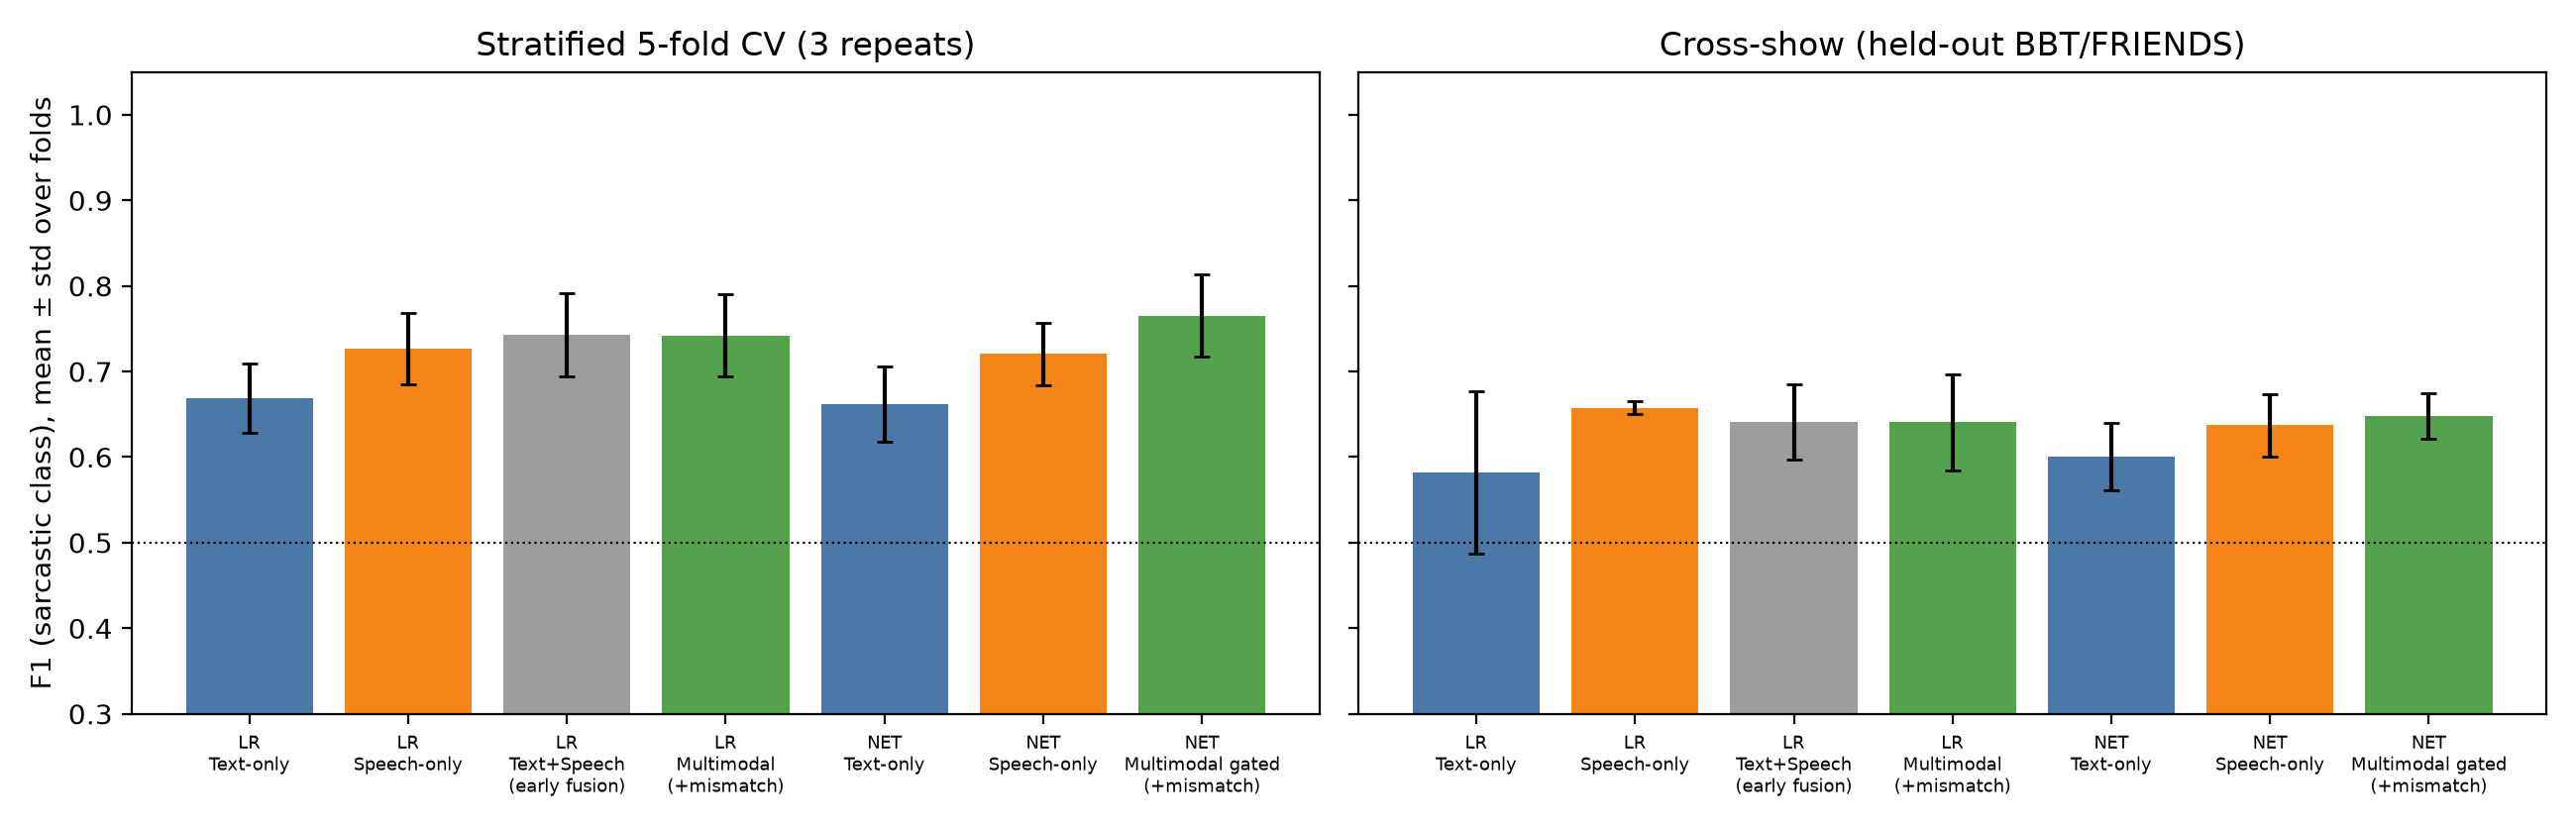

In [14]:
# ---- Figures -----------------------------------------------------------------------------------------
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
FIG = OUT/"figures"
main = ["LR|Text-only", "LR|Speech-only", "LR|Text+Speech (early fusion)", "LR|Multimodal (+mismatch)",
        "NET|Text-only", "NET|Speech-only", "NET|Multimodal gated (+mismatch)"]
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (nm, s) in zip(axs, ((f"Stratified {CFG['n_splits']}-fold CV ({CFG['n_repeats']} repeats)", sumA), ("Cross-show (held-out " + "/".join(TEST_SHOWS) + ")", sumB))):
    s2 = s.loc[main]; ax.bar(range(len(main)), s2.f1_mean, yerr=s2.f1_std, capsize=3,
                              color=["#4c78a8", "#f58518", "#9d9d9d", "#54a24b", "#4c78a8", "#f58518", "#54a24b"])
    ax.set_xticks(range(len(main))); ax.set_xticklabels([m.replace("|", "\n").replace(" (", "\n(") for m in main], fontsize=6.5, rotation=0)
    ax.set_title(nm); ax.axhline(0.5, ls=":", c="k", lw=.8); ax.set_ylim(0.3, 1.05)
axs[0].set_ylabel("F1 (sarcastic class), mean ± std over folds"); plt.tight_layout(); plt.savefig(FIG/"f1_comparison.png", dpi=200); plt.close()

fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, m in zip(axs, ("LR|Text-only", "LR|Speech-only", "LR|Multimodal (+mismatch)")):
    ConfusionMatrixDisplay(confusion_matrix(y, (oofA[m][0] >= .5).astype(int)), display_labels=["non-sarc", "sarc"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(m.split("|")[1], fontsize=10)
plt.tight_layout(); plt.savefig(FIG/"confusion_matrices.png", dpi=200); plt.close()

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
axs[0].boxplot([ad[y == 0], ad[y == 1]], showmeans=True)
axs[0].set_xticks([1, 2]); axs[0].set_xticklabels(["non-sarcastic", "sarcastic"])
axs[0].set_ylabel("|text valence − speech valence|"); axs[0].set_title("Text/tone mismatch by class")
sc = axs[1].scatter(text_val, speech_val, c=y, cmap="coolwarm", s=10, alpha=.6)
axs[1].axhline(0, c="k", lw=.5); axs[1].axvline(0, c="k", lw=.5)
axs[1].set_xlabel("text valence (RoBERTa sentiment)"); axs[1].set_ylabel("speech valence (emotion model)"); axs[1].set_title("red = sarcastic")
plt.tight_layout(); plt.savefig(FIG/"mismatch.png", dpi=200); plt.close()

g = gatesA.get("NET|Multimodal gated (+mismatch)")
if g is not None:
    plt.figure(figsize=(6, 3.2)); plt.bar(MULTI, g, color="#54a24b"); plt.xticks(rotation=30, ha="right")
    plt.ylabel("mean gate weight"); plt.title("Learned modality weights (CV)"); plt.tight_layout(); plt.savefig(FIG/"gate_weights.png", dpi=200); plt.close()
print(sorted(p.name for p in FIG.iterdir()))
from IPython.display import Image, display
display(Image(str(FIG/"f1_comparison.png")))

In [15]:
# ======================= FINAL CELL: generate METHOD + REPORT (+ LaTeX tables, zip) =======================
import importlib.metadata as im, datetime, re
OUT = Path(OUT); FIG = OUT/"figures"
rA, rB = pd.read_csv(OUT/"results_cv.csv", index_col=0), pd.read_csv(OUT/"results_loso.csv", index_col=0)
sig = pd.read_csv(OUT/"significance.csv"); mm = pd.read_csv(OUT/"mismatch_analysis.csv")
mms = json.load(open(OUT/"mismatch_stats.json")); gA = json.load(open(OUT/"gates_cv.json"))
ver = lambda p: im.version(p) if p else "n/a"
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
elapsed = (time.time()-T0)/60
price = float(os.environ.get("VAST_PRICE_PER_HOUR", "nan"))

def pm(s, k): return f"{s[k+'_mean']:.3f} ± {s[k+'_std']:.3f}"
def table(r, models=None):
    r = r if models is None else r.loc[[m for m in models if m in r.index]]
    d = pd.DataFrame({"Model": r.index, "Acc": [pm(x, "acc") for _, x in r.iterrows()], "Prec": [pm(x, "precision") for _, x in r.iterrows()],
                      "Rec": [pm(x, "recall") for _, x in r.iterrows()], "F1": [pm(x, "f1") for _, x in r.iterrows()],
                      "Macro-F1": [pm(x, "macro_f1") for _, x in r.iterrows()]})
    d["Model"] = d["Model"].str.replace("|", ": ", regex=False)
    return d
def md_table(d): return d.to_markdown(index=False)

main = ["LR|Text-only", "LR|Speech-only", "LR|Text+Speech (early fusion)", "LR|Multimodal (+mismatch)",
        "NET|Text-only", "NET|Speech-only", "NET|Multimodal gated (+mismatch)"]
abl = ["LR|Multimodal (+mismatch)", "LR|Multimodal -mismatch", "LR|Multimodal -prosody", "LR|Multimodal -WavLM",
       "LR|Prosody-only", "LR|Mismatch-only", "LR|Text+Context", "LR|Text-only"]
n = len(meta); npos = int(meta.sarcasm.sum())
block_dims = {k: v.shape[1] for k, v in B.items()}

# ---------- auto findings (statements are conditional on the numbers actually obtained) ----------
def f1(r, m): return r.loc[m, "f1_mean"]
find = []
for nm, r, tag in (("stratified CV", rA, "cv"), ("cross-show", rB, "loso")):
    for clf, full, txt, sp in (("LR", "LR|Multimodal (+mismatch)", "LR|Text-only", "LR|Speech-only"),
                               ("gated net", "NET|Multimodal gated (+mismatch)", "NET|Text-only", "NET|Speech-only")):
        s = sig[(sig.protocol == tag) & (sig.model_a == full) & (sig.model_b == txt)].iloc[0]
        verdict = ("a statistically reliable gain" if s.ci_low > 0 else "a decrease" if s.ci_high < 0 else "no reliable difference (CI includes 0)")
        find.append(f"- **{nm}, {clf}:** multimodal F1 {f1(r, full):.3f} vs text-only {f1(r, txt):.3f} and speech-only {f1(r, sp):.3f}; "
                    f"ΔF1 vs text = {s.delta_f1:+.3f} (95% bootstrap CI [{s.ci_low:+.3f}, {s.ci_high:+.3f}]) → {verdict}.")
hi, lo = mm[(mm.subset.str.startswith("high")) & (mm.model == "LR|Multimodal (+mismatch)")].iloc[0], mm[(mm.subset.str.startswith("low")) & (mm.model == "LR|Multimodal (+mismatch)")].iloc[0]
hi_t, lo_t = mm[(mm.subset.str.startswith("high")) & (mm.model == "LR|Text-only")].iloc[0], mm[(mm.subset.str.startswith("low")) & (mm.model == "LR|Text-only")].iloc[0]
find.append(f"- **Contradiction subset (RQ):** in the top-third text/tone-mismatch utterances (n={int(hi.n)}) multimodal F1 = {hi.f1:.3f} vs text-only {hi_t.f1:.3f} "
            f"(gain {hi.f1-hi_t.f1:+.3f}); in the bottom third (n={int(lo.n)}) multimodal {lo.f1:.3f} vs text-only {lo_t.f1:.3f} (gain {lo.f1-lo_t.f1:+.3f}).")
find.append(f"- **Mismatch signal:** mean |text valence − speech valence| is {mms['mean_abs_diff_sarcastic']:.3f} for sarcastic vs {mms['mean_abs_diff_nonsarcastic']:.3f} for non-sarcastic "
            f"utterances (Mann–Whitney p = {mms['mannwhitney_p']:.3g}); polarity-flip rate {mms['flip_rate_sarcastic']:.1%} vs {mms['flip_rate_nonsarcastic']:.1%}.")
if gA:
    gm = gA.get("NET|Multimodal gated (+mismatch)")
    if gm: find.append("- **Learned modality weights (gated net, CV):** " + ", ".join(f"{k}={v:.2f}" for k, v in zip(MULTI, gm)) + ".")

# ---------- METHOD ----------
method = f"""# Method

## 1. Task and data
Binary sarcasm detection on **MUStARD** (Castro et al., ACL 2019): {n} audiovisual utterances from *Friends*, *The Big Bang Theory*, *The Golden Girls* and
*Sarcasmaholics Anonymous* ({npos} sarcastic / {n-npos} non-sarcastic; shows: {', '.join(f'{s} ({c})' for s, c in meta.show.value_counts().items())}).
Each item has the transcript of the target utterance, the preceding dialogue context, speaker, show, and the utterance video clip. We use the **utterance transcript and the utterance audio only**
(video frames are not used because the project studies text + speech prosody; context text is used only in one ablation).
Audio is extracted with ffmpeg to 16 kHz mono PCM (mean clip length {meta.dur.mean():.1f} s).

## 2. Feature extraction (all encoders frozen; extracted once and cached)
| Block | Dim | Description |
|---|---|---|
| `text_emb` | {block_dims['text_emb']} | `{CFG['text_model']}` mean-pooled last hidden layer of the utterance |
| `text_sent` | {block_dims['text_sent']} | `{CFG['sentiment_model']}` posteriors [neg, neu, pos] ("what is said") |
| `textctx_emb` | {block_dims['textctx_emb']} | same encoder on the (utterance, context) sentence pair (ablation only) |
| `wavlm` | {block_dims['wavlm']} | `{CFG['speech_model']}`: mean+std over time of the average of the middle third of transformer layers |
| `prosody` | {block_dims['prosody']} | librosa: pYIN F0 (mean, P10/P90, std & range in semitones, slope, voiced fraction, jitter proxy), RMS energy (mean/std/max/dynamic range/slope, shimmer proxy), speaking rate (words/s from the transcript, articulation rate excluding pauses, onset rate), pauses (count, total, ratio, mean, max; silence gaps ≥150 ms at 30 dB), spectral centroid/flatness/rolloff/ZCR, 13 MFCC mean+std |
| `speech_emo` | {block_dims['speech_emo']} | `{CFG['emotion_model']}` posteriors over {EMO_LABELS} ("how it is said") |
| `mismatch` | {block_dims['mismatch']} | explicit incongruity features: text valence = P(pos)−P(neg); speech valence = Σ P(emotion)·v(emotion) with v(happy)=+1, v(angry/sad)=−1, v(neutral)=0; then valence difference, |difference|, product, and a polarity-flip flag (opposite signs, both |·|>0.1) |

## 3. Models (text-only vs speech-only vs multimodal)
* **Logistic regression (LR):** blocks standardised on the training fold only, clipped to ±5, each block scaled by 1/√dim so no block dominates, concatenated (early fusion); L2 strength chosen by inner 3-fold CV on the training fold (log-loss), balanced class weights.
* **Gated-fusion network (NET):** one projection (Dropout→Linear({CFG['net_hidden']})→LayerNorm→GELU→Dropout({CFG['net_dropout']})) per block; a sample-wise softmax gate over the modality blocks weights the projections; MLP head. AdamW (lr {CFG['net_lr']}, wd {CFG['net_wd']}), one-cycle schedule, {CFG['net_epochs']} epochs, batch {CFG['net_bs']}, label smoothing 0.1, average of {CFG['net_seeds']} seeds. **Hyper-parameters were fixed a priori and not tuned on test folds.**
* **Text-only** = `text_emb`+`text_sent`; **Speech-only** = `wavlm`+`prosody`+`speech_emo`; **Multimodal** = all of them + `mismatch`.
* **Ablations:** remove mismatch / prosody / WavLM; prosody-only; mismatch-only (sentiment+emotion posteriors+mismatch); text with dialogue context.

## 4. Evaluation protocol
* **A. Repeated stratified {CFG['n_splits']}-fold CV × {CFG['n_repeats']} repeats** (random split; speakers/shows overlap between train and test — optimistic).
* **B. Cross-show test** (train on all other shows, test on each of {', '.join(TEST_SHOWS)} — the only shows containing both classes; GOLDENGIRLS and SARCASMOHOLICS are ~100 % sarcastic and stay in training). The held-out show's speakers and acoustic conditions are unseen — the harder, more realistic setting.
* Metrics at threshold 0.5: accuracy, precision, recall, F1 (sarcastic = positive class), macro-F1; mean ± std over folds.
* **Significance:** paired bootstrap ({CFG['bootstrap']} resamples) of ΔF1 on pooled out-of-fold predictions (first repeat).
* **Research-question analysis:** utterances are split by tertiles of |text valence − speech valence| (and by polarity flip) and models are compared per subset.

## 5. Reproducibility
Seed {CFG['seed']}; GPU: {gpu}; torch {ver('torch')}, transformers {ver('transformers')}, librosa {ver('librosa')}, scikit-learn {ver('scikit-learn')}; Python {platform.python_version()}.
Total wall-clock of this notebook run: {elapsed:.1f} min{f' (≈ ${elapsed/60*price:.2f} at ${price}/h)' if price == price else ''}.
Data: https://github.com/soujanyaporia/MUStARD (annotations); video clips from the HuggingFace mirror `MichiganNLP/MUStARD`.
"""
(OUT/"method.md").write_text(method)

# ---------- REPORT ----------
report = f"""# SarcasTone: Multimodal Sarcasm Detection Using Text and Speech Prosody
*Auto-generated {datetime.datetime.now():%Y-%m-%d %H:%M} — numbers below come from this run; re-read them before copying into the paper.*

## Research question
How effectively can combining textual information and speech prosody improve sarcasm detection when the speaker's tone contradicts the literal meaning of the words?

{method}

## 6. Results

### 6.1 Main comparison — stratified {CFG['n_splits']}-fold CV ({CFG['n_repeats']} repeats)
{md_table(table(rA, main))}

### 6.2 Main comparison — cross-show (held-out {', '.join(TEST_SHOWS)}; mean ± std over {len(TEST_SHOWS)} folds)
{md_table(table(rB, main))}

Pooled over all held-out utterances:
{md_table(poolB.loc[[m for m in main if m in poolB.index]].round(3).reset_index().rename(columns={'index': 'Model'}))}

![F1 comparison](figures/f1_comparison.png)

### 6.3 Ablations (CV)
{md_table(table(rA, abl))}

### 6.4 Ablations (cross-show)
{md_table(table(rB, abl))}

### 6.5 Significance of multimodal vs unimodal (ΔF1, paired bootstrap)
{md_table(sig.round(3))}

### 6.6 Text/tone mismatch analysis (CV out-of-fold predictions)
{md_table(mm.pivot_table(index=['subset', 'n'], columns='model', values='f1').round(3).reset_index())}

![Mismatch](figures/mismatch.png)
![Confusion matrices](figures/confusion_matrices.png)

## 7. Key findings (auto-generated from the numbers above)
{chr(10).join(find)}

## 8. Limitations (state these in the paper)
* **Small dataset** ({n} utterances) → high variance; fold std and bootstrap CIs are reported; differences within CI are not evidence.
* **Show/speaker confound & laugh tracks:** sitcom audio contains canned laughter and show-specific acoustics; models may exploit these instead of prosody. The cross-show test partly controls for this; note that in MUStARD the show is correlated with the label (GOLDENGIRLS/SARCASMOHOLICS are almost all sarcastic), so random-split CV can be inflated by show identity.
* **Domain shift of the pretrained emotion model** (trained on acted IEMOCAP-style speech) → the speech valence used for the mismatch features is noisy.
* **Fixed hyper-parameters** (no test-set tuning) — may under-fit the neural head; CV repeats are not independent, so CV standard deviations are optimistic.
* Context and video are not used in the main models; sarcasm often needs dialogue context (see Text+Context ablation).

## References
[1] S. Castro, D. Hazarika, V. Pérez-Rosas, R. Zimmermann, R. Mihalcea, S. Poria, "Towards multimodal sarcasm detection (an *obviously* perfect paper)," in *Proc. ACL*, 2019, pp. 4619–4629.
[2] Y. Liu *et al.*, "RoBERTa: A robustly optimized BERT pretraining approach," arXiv:1907.11692, 2019.
[3] S. Chen *et al.*, "WavLM: Large-scale self-supervised pre-training for full stack speech processing," *IEEE J. Sel. Topics Signal Process.*, vol. 16, no. 6, 2022.
[4] S. Yang *et al.*, "SUPERB: Speech processing universal performance benchmark," in *Proc. Interspeech*, 2021.
[5] M. Mauch and S. Dixon, "pYIN: A fundamental frequency estimator using probabilistic threshold distributions," in *Proc. ICASSP*, 2014.
[6] B. McFee *et al.*, "librosa: Audio and music signal analysis in Python," in *Proc. SciPy*, 2015.
[7] A. Ray, S. Mishra, A. Nunna, P. Bhattacharyya, "A multimodal corpus for emotion recognition in sarcasm," in *Proc. LREC*, 2022 (MUStARD++, suggested extension).
"""
(OUT/"report.md").write_text(report)

# ---------- LaTeX tables for the IEEE paper ----------
for nm, r in (("cv", rA), ("loso", rB)):
    t = table(r, main); t.columns = ["Model", "Acc", "Prec", "Rec", "F1", "Macro-F1"]
    (OUT/f"table_{nm}.tex").write_text(t.to_latex(index=False, escape=True))
# ======================= PDF REPORT (reportlab) =======================
import matplotlib, html as _html
from reportlab.lib.pagesizes import A4
from reportlab.lib import colors
from reportlab.lib.units import cm
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image as RLImage, PageBreak, KeepTogether
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont

_fd = Path(matplotlib.get_data_path())/"fonts"/"ttf"            # DejaVu ships with matplotlib -> supports ± Δ − → √ Σ
try:
    pdfmetrics.registerFont(TTFont("DV", str(_fd/"DejaVuSans.ttf"))); pdfmetrics.registerFont(TTFont("DV-B", str(_fd/"DejaVuSans-Bold.ttf")))
    pdfmetrics.registerFont(TTFont("DV-I", str(_fd/"DejaVuSans-Oblique.ttf")))
    from reportlab.lib.fonts import addMapping
    addMapping("DV", 0, 0, "DV"); addMapping("DV", 1, 0, "DV-B"); addMapping("DV", 0, 1, "DV-I"); addMapping("DV", 1, 1, "DV-B")
    FONT, FONTB = "DV", "DV-B"
except Exception as e:
    print("DejaVu not found, falling back to Helvetica:", e); FONT, FONTB = "Helvetica", "Helvetica-Bold"

ss = getSampleStyleSheet()
st = {k: ParagraphStyle(k, parent=ss[p], fontName=f, fontSize=s, leading=s*1.3, spaceAfter=a)
      for k, p, f, s, a in (("t", "Title", FONTB, 17, 6), ("h1", "Heading1", FONTB, 13, 4), ("h2", "Heading2", FONTB, 10.5, 3),
                             ("b", "BodyText", FONT, 8.6, 4), ("s", "BodyText", FONT, 7.4, 2), ("c", "BodyText", FONT, 6.6, 0))}
def md(s):   # minimal markdown -> reportlab markup
    s = _html.escape(str(s), quote=False)
    s = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", s); s = re.sub(r"`(.+?)`", r"<font size=7>\1</font>", s)
    s = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", s)
    return s
P = lambda s, k="b": Paragraph(md(s), st[k])
def df_table(d, col_w=None, font_k="c", hl_best=None):
    d = d.copy()
    data = [[Paragraph(f"<b>{md(c)}</b>", st[font_k]) for c in d.columns]]
    for _, r in d.iterrows():
        data.append([Paragraph(md(f"{v:.3f}" if isinstance(v, (float, np.floating)) else v), st[font_k]) for v in r.values])
    W = 17.5*cm
    if col_w is None: col_w = [W*0.34] + [W*0.66/(len(d.columns)-1)]*(len(d.columns)-1)
    t = Table(data, colWidths=col_w, repeatRows=1)
    sty = [("GRID", (0, 0), (-1, -1), 0.25, colors.grey), ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#dde6f0")),
           ("VALIGN", (0, 0), (-1, -1), "MIDDLE"), ("TOPPADDING", (0, 0), (-1, -1), 1.5), ("BOTTOMPADDING", (0, 0), (-1, -1), 1.5)]
    for i in range(1, len(data)):
        if i % 2 == 0: sty.append(("BACKGROUND", (0, i), (-1, i), colors.HexColor("#f6f8fa")))
    if hl_best is not None: sty.append(("BACKGROUND", (0, hl_best+1), (-1, hl_best+1), colors.HexColor("#d9f2d9")))
    t.setStyle(TableStyle(sty)); return t
def fig(name, width=17*cm):
    p = FIG/name
    if not p.exists(): return Spacer(1, 1)
    from PIL import Image as _PI
    w, h = _PI.open(p).size
    return RLImage(str(p), width=width, height=width*h/w)
def best_row(d, col="F1"):
    try: return int(np.argmax([float(str(v).split()[0]) for v in d[col]]))
    except Exception: return None

tA, tB = table(rA, main), table(rB, main)
pdf_path = OUT/"SarcasTone_Report.pdf"
doc = SimpleDocTemplate(str(pdf_path), pagesize=A4, leftMargin=1.7*cm, rightMargin=1.7*cm, topMargin=1.5*cm, bottomMargin=1.5*cm,
                        title="SarcasTone report", author="SarcasTone notebook")
E = []
E += [P("SarcasTone: Multimodal Sarcasm Detection Using Text and Speech Prosody", "t"),
      P(f"Auto-generated {datetime.datetime.now():%Y-%m-%d %H:%M} | GPU: {gpu} | CPUs: {NJOBS} | wall-clock {elapsed:.1f} min"
        + (f" | est. cost ${elapsed/60*price:.2f} at ${price:.2f}/h" if price == price else ""), "s"),
      Spacer(1, 4),
      P("**Research question.** How effectively can combining textual information and speech prosody improve sarcasm detection when the speaker's tone contradicts the literal meaning of the words?"),
      P("Key findings", "h1")] + [P(f.lstrip("- "), "b") for f in find]

E += [P("1. Data", "h1"),
      P(f"MUStARD (Castro et al., ACL 2019): {n} utterances ({npos} sarcastic / {n-npos} non-sarcastic). Utterance transcript + utterance audio "
        f"(ffmpeg, 16 kHz mono, mean {meta.dur.mean():.1f} s). Video frames are not used; dialogue context only in one ablation."),
      df_table(meta.groupby("show").sarcasm.agg(n="count", sarcastic="sum").assign(frac_sarcastic=lambda d: d.sarcastic/d.n).reset_index(),
               col_w=[5*cm, 3*cm, 3*cm, 3*cm]),
      P("2. Features (frozen encoders, extracted once)", "h1"),
      df_table(pd.DataFrame([("text_emb", block_dims["text_emb"], f"{CFG['text_model']} mean-pooled utterance embedding"),
                             ("text_sent", block_dims["text_sent"], f"{CFG['sentiment_model']} [neg, neu, pos] - what is said"),
                             ("textctx_emb", block_dims["textctx_emb"], "same encoder on (utterance, context) pair - ablation"),
                             ("wavlm", block_dims["wavlm"], f"{CFG['speech_model']} mid-layer mean+std pooling"),
                             ("prosody", block_dims["prosody"], "pYIN F0 stats, energy, words/s, articulation rate, pauses, spectral, MFCC"),
                             ("speech_emo", block_dims["speech_emo"], f"{CFG['emotion_model']} posteriors {EMO_LABELS} - how it is said"),
                             ("mismatch", block_dims["mismatch"], "text valence vs speech valence: diff, |diff|, product, polarity flip")],
                            columns=["Block", "Dim", "Description"]), col_w=[2.8*cm, 1.4*cm, 13.3*cm]),
      P("3. Models and protocol", "h1"),
      P(f"**LR**: per-block standardisation on train folds, 1/sqrt(dim) block scaling, L2 strength chosen by inner 3-fold CV, balanced class weights. "
        f"**NET**: gated fusion (per-block projection to {CFG['net_hidden']} units, sample-wise softmax gate over modalities, MLP head), "
        f"{CFG['net_epochs']} epochs, {CFG['net_seeds']}-seed average, fixed hyper-parameters. "
        f"**A**: stratified {CFG['n_splits']}-fold CV x {CFG['n_repeats']} repeats. **B**: cross-show test on {', '.join(TEST_SHOWS)}. "
        f"Threshold 0.5; sarcastic = positive class. Significance: paired bootstrap ({CFG['bootstrap']} resamples) of delta-F1 on pooled out-of-fold predictions.")]

E += [PageBreak(), P("4. Results", "h1"),
      P(f"4.1 Stratified {CFG['n_splits']}-fold CV ({CFG['n_repeats']} repeats), mean ± std over folds", "h2"), df_table(tA, hl_best=best_row(tA)), Spacer(1, 6),
      P(f"4.2 Cross-show (held-out {', '.join(TEST_SHOWS)}), mean ± std over folds", "h2"), df_table(tB, hl_best=best_row(tB)), Spacer(1, 4),
      P("Pooled over all held-out utterances", "s"),
      df_table(poolB.loc[[m for m in main if m in poolB.index]].reset_index().rename(columns={"index": "Model"})
               .assign(Model=lambda d: d.Model.str.replace("|", ": ", regex=False))), Spacer(1, 6),
      KeepTogether([fig("f1_comparison.png")]),
      P("4.3 Ablations (CV)", "h2"), df_table(table(rA, abl)),
      P("4.4 Ablations (cross-show)", "h2"), df_table(table(rB, abl)),
      P("4.5 Significance: multimodal vs unimodal (paired bootstrap, delta-F1 with 95% CI)", "h2"),
      df_table(sig.assign(model_a=sig.model_a.str.replace("|", ": ", regex=False), model_b=sig.model_b.str.replace("|", ": ", regex=False)),
               col_w=[1.6*cm, 4.6*cm, 4.6*cm, 1.7*cm, 1.7*cm, 1.7*cm, 1.6*cm]),
      PageBreak(), P("5. Text/tone mismatch analysis (research question)", "h1"),
      P(f"Mean |text valence - speech valence|: sarcastic {mms['mean_abs_diff_sarcastic']:.3f} vs non-sarcastic {mms['mean_abs_diff_nonsarcastic']:.3f} "
        f"(Mann-Whitney p = {mms['mannwhitney_p']:.3g}); polarity-flip rate {mms['flip_rate_sarcastic']:.1%} vs {mms['flip_rate_nonsarcastic']:.1%}. "
        "F1 per subset (CV out-of-fold predictions):")]
pv = mm.pivot_table(index=["subset", "n"], columns="model", values="f1").reset_index()
pv.columns = [str(c).replace("|", ": ") for c in pv.columns]
E += [df_table(pv, col_w=[4.3*cm, 1.0*cm] + [12.2*cm/(len(pv.columns)-2)]*(len(pv.columns)-2)), Spacer(1, 6),
      fig("mismatch.png", 15*cm), fig("confusion_matrices.png", 16*cm), fig("gate_weights.png", 10*cm)]
top_pros = pros_df.assign(_y=y).groupby("_y").mean().T
top_pros.columns = ["non-sarcastic", "sarcastic"]
_pv = {c: mannwhitneyu(pros_df[c][y == 1], pros_df[c][y == 0]).pvalue for c in pros_df.columns}
top_pros["p_value"] = pd.Series(_pv)
top_pros = top_pros.sort_values("p_value").head(12).reset_index().rename(columns={"index": "prosodic feature"})
E += [P("6. Most discriminative hand-crafted prosodic features (class means, Mann-Whitney U, uncorrected)", "h2"),
      df_table(top_pros, col_w=[5.5*cm, 4*cm, 4*cm, 4*cm])]
E += [P("7. Limitations", "h1")] + [P(x, "b") for x in (
      f"Small dataset ({n} utterances): high variance; differences inside the bootstrap CI are not evidence.",
      "Show/speaker confound and laugh tracks: GOLDENGIRLS and SARCASMOHOLICS are almost all sarcastic, so random-split CV can partly learn show identity; the cross-show test controls for this.",
      "The speech-emotion model was trained on acted speech (IEMOCAP), so the speech valence used for mismatch features is noisy.",
      "Hyper-parameters fixed a priori (no test tuning); CV repeats are not independent, so their std is optimistic.")]
E += [P("8. Reproducibility", "h1"),
      P(f"Seed {CFG['seed']}; torch {ver('torch')}, transformers {ver('transformers')}, librosa {ver('librosa')}, scikit-learn {ver('scikit-learn')}, "
        f"Python {platform.python_version()}. Data: github.com/soujanyaporia/MUStARD; clips: huggingface.co/datasets/MichiganNLP/MUStARD.", "s")]

def _footer(c, d):
    c.saveState(); c.setFont(FONT, 7); c.setFillColor(colors.grey)
    c.drawRightString(A4[0]-1.7*cm, 0.9*cm, f"SarcasTone report - page {d.page}"); c.restoreState()
doc.build(E, onFirstPage=_footer, onLaterPages=_footer)
print("PDF report:", pdf_path)

zp = shutil.make_archive(str(ROOT/"sarcastone_outputs"), "zip", OUT)
print("Wrote:", *[p.name for p in sorted(OUT.iterdir())], sep="\n  ")
print("\nDOWNLOAD:", zp, f"| elapsed {elapsed:.1f} min")
from IPython.display import Markdown, display
display(Markdown("\n".join(find)))

PDF report: /Users/raghav/Desktop/TrueTone/sarcastone/outputs/SarcasTone_Report.pdf
Wrote:
  SarcasTone_Report.pdf
  figures
  folds_cv.csv
  folds_loso.csv
  gates_cv.json
  gates_loso.json
  method.md
  mismatch_analysis.csv
  mismatch_stats.json
  oof_cv.npz
  oof_loso.npz
  report.md
  results_cv.csv
  results_loso.csv
  results_loso_pooled.csv
  significance.csv
  table_cv.tex
  table_loso.tex

DOWNLOAD: /Users/raghav/Desktop/TrueTone/sarcastone/sarcastone_outputs.zip | elapsed 10.8 min


- **stratified CV, LR:** multimodal F1 0.742 vs text-only 0.669 and speech-only 0.727; ΔF1 vs text = +0.067 (95% bootstrap CI [+0.032, +0.101]) → a statistically reliable gain.
- **stratified CV, gated net:** multimodal F1 0.765 vs text-only 0.662 and speech-only 0.721; ΔF1 vs text = +0.090 (95% bootstrap CI [+0.049, +0.129]) → a statistically reliable gain.
- **cross-show, LR:** multimodal F1 0.641 vs text-only 0.582 and speech-only 0.658; ΔF1 vs text = +0.065 (95% bootstrap CI [+0.028, +0.103]) → a statistically reliable gain.
- **cross-show, gated net:** multimodal F1 0.648 vs text-only 0.600 and speech-only 0.637; ΔF1 vs text = +0.049 (95% bootstrap CI [+0.012, +0.088]) → a statistically reliable gain.
- **Contradiction subset (RQ):** in the top-third text/tone-mismatch utterances (n=230) multimodal F1 = 0.664 vs text-only 0.603 (gain +0.061); in the bottom third (n=230) multimodal 0.792 vs text-only 0.726 (gain +0.066).
- **Mismatch signal:** mean |text valence − speech valence| is 0.542 for sarcastic vs 0.621 for non-sarcastic utterances (Mann–Whitney p = 0.0504); polarity-flip rate 27.8% vs 30.4%.
- **Learned modality weights (gated net, CV):** text_emb=0.31, text_sent=0.00, wavlm=0.68, prosody=0.00, speech_emo=0.00, mismatch=0.00.